# Modelos lineales explicados fácil · Regresión lineal y regresión logística
**Diseño de Soluciones de Inteligencia Artificial (CERTUS) · Sesión 5 · Tema 8**

> **Cómo usar este cuaderno:** ejecuta las celdas de arriba hacia abajo (botón ▶ o `Shift + Enter`). Lee primero el texto de cada sección, luego mira el resultado. No necesitas saber programar: lo importante es **entender qué hace cada parámetro** y ver el efecto en los gráficos.

## ¿Qué vas a aprender?
1. Qué es un modelo lineal y para qué sirve (con analogías).
2. **Regresión lineal**: predecir un número (por ejemplo, el monto de una factura).
3. **Regresión logística**: predecir una categoría (por ejemplo, "se va / se queda") con una probabilidad.
4. Los **parámetros** que se pueden modificar (`C`, `penalty`, `class_weight`, `max_iter`, `alpha`...), qué significan y qué pasa si los cambias.
5. Cómo **interpretar** el modelo: qué variables empujan hacia "se va".
6. Cuándo **no** funciona un modelo lineal y qué hacer.

### Palabras que vas a ver
| Palabra | Significado fácil |
|---|---|
| **Parámetro (del modelo)** | Lo que el modelo *aprende solo* de los datos (por ejemplo, los coeficientes). Tú no lo eliges. |
| **Hiperparámetro** | Una "perilla" que *tú configuras antes de entrenar* (por ejemplo, `C`). Es lo que vamos a mover en este cuaderno. |
| **Entrenar (`fit`)** | Dejar que el modelo aprenda de los datos. |
| **Predecir (`predict`)** | Usar el modelo ya entrenado con datos nuevos. |
| **Overfitting** | El modelo se aprende los datos "de memoria" y falla con datos nuevos. |
| **Underfitting** | El modelo es tan simple que ni siquiera aprende lo básico. |

## 0. Preparación (ejecuta esta celda primero)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.datasets import make_moons, make_blobs, make_circles, make_classification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

SEMILLA = 42
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def frontera(modelo, X, y, ax=None, titulo=""):
    # Dibuja la 'frontera de decisión' de un modelo entrenado con 2 variables:
    # el fondo rojo/azul muestra qué predice el modelo en cada punto del plano.
    ax = ax or plt.gca()
    modelo.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 250),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 250))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    return modelo


def metricas(modelo, Xv, yv):
    # Calcula las métricas principales de un modelo ya entrenado.
    pred = modelo.predict(Xv)
    if hasattr(modelo, "predict_proba"):
        puntaje = modelo.predict_proba(Xv)[:, 1]
    else:
        puntaje = modelo.decision_function(Xv)
    return pd.Series({
        "exactitud": accuracy_score(yv, pred),
        "precisión": precision_score(yv, pred, zero_division=0),
        "recall": recall_score(yv, pred),
        "F1": f1_score(yv, pred),
        "AUC": roc_auc_score(yv, puntaje),
    }).round(3)

## 1. Idea central: una recta (o un plano) que resume la relación
Imagina que quieres estimar cuánto pagará de factura un cliente según los GB que consume. Si dibujas los clientes en un gráfico, suelen formar una nube de puntos que sube de izquierda a derecha. Un **modelo lineal** dibuja la **mejor recta** que pasa por esa nube.

La fórmula de la recta es la de secundaria:

**factura = a + b × GB**

* **`b` (coeficiente o pendiente):** cuánto sube la factura por cada GB adicional.
* **`a` (intercepto):** cuánto se paga aunque se consuma 0 GB (por ejemplo, el cargo fijo del plan).

Con varias variables es lo mismo, solo que se suman más términos:
**factura = a + b₁·GB + b₂·minutos + b₃·líneas ...**

### Ejemplo 1 · Regresión lineal (predecir un número)
Vamos a **inventar** datos con una regla conocida (factura = 20 + 8 × GB, más algo de ruido) para comprobar que el modelo es capaz de "descubrir" esa regla por sí solo.

In [2]:
from sklearn.linear_model import LinearRegression

rng = np.random.RandomState(0)
gb = rng.uniform(1, 20, 40)                       # GB consumidos por 40 clientes (inventados)
factura = 20 + 8 * gb + rng.normal(0, 12, 40)     # regla real + ruido (las cosas reales nunca son exactas)

X = gb.reshape(-1, 1)                             # sklearn pide las variables en columnas
modelo = LinearRegression()
modelo.fit(X, factura)                            # <- aquí el modelo APRENDE

print("Intercepto (a):", round(modelo.intercept_, 2), "   (la regla real era 20)")
print("Coeficiente (b):", round(modelo.coef_[0], 2), "   (la regla real era 8)")
print("Predicción para 10 GB: S/", round(modelo.predict([[10]])[0], 2))
print("(No salen exactos porque los datos tienen ruido; con más clientes se acercarían más a 20 y 8.)")

Intercepto (a): 13.78    (la regla real era 20)
Coeficiente (b): 8.16    (la regla real era 8)
Predicción para 10 GB: S/ 95.43
(No salen exactos porque los datos tienen ruido; con más clientes se acercarían más a 20 y 8.)


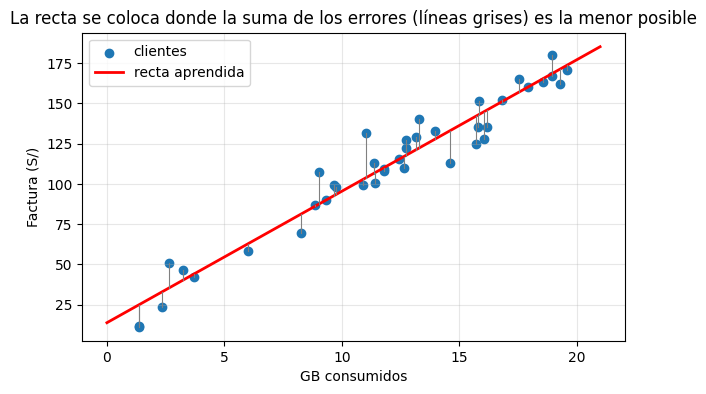

In [3]:
plt.scatter(gb, factura, label="clientes")
xs = np.linspace(0, 21, 50).reshape(-1, 1)
plt.plot(xs, modelo.predict(xs), color="red", lw=2, label="recta aprendida")
for xi, yi, pi in zip(gb, factura, modelo.predict(X)):          # líneas grises = errores (residuos)
    plt.plot([xi, xi], [yi, pi], color="gray", lw=.8)
plt.xlabel("GB consumidos"); plt.ylabel("Factura (S/)")
plt.title("La recta se coloca donde la suma de los errores (líneas grises) es la menor posible")
plt.legend(); plt.show()

**¿Cómo "aprende" la recta?** Prueba muchas rectas y se queda con la que **minimiza el error cuadrático** (suma de las distancias grises al cuadrado). A eso se le llama *mínimos cuadrados*.

### Parámetros de `LinearRegression`
| Parámetro | Para qué sirve | Valor por defecto | Cuándo moverlo |
|---|---|---|---|
| `fit_intercept` | ¿Calcular el intercepto `a`? | `True` | Casi nunca. Ponlo en `False` solo si sabes que la recta debe pasar por el origen (0, 0). |
| `positive` | Obliga a que todos los coeficientes sean ≥ 0 | `False` | Cuando por lógica del negocio una variable *no puede* restar (ej.: más GB nunca baja la factura). |
| `n_jobs` | Usar varios núcleos del computador | `None` | Solo en datos enormes. |

> **Dato clave:** la regresión lineal "pura" **casi no tiene perillas**. Eso la hace simple y estable, pero también puede sobreajustarse si hay muchas variables. Para eso existen **Ridge** y **Lasso** (siguiente ejemplo).

### Ejemplo 2 · Ridge: cuando el modelo "se pasa de listo"
Si le damos al modelo demasiada libertad (una curva muy flexible), se aprende hasta el ruido: **overfitting**. **Ridge** agrega un "freno": penaliza los coeficientes muy grandes. La perilla se llama **`alpha`**:

* `alpha` muy chico (casi 0) → casi sin freno → curva loca (overfitting).
* `alpha` moderado → curva suave y razonable.
* `alpha` enorme → freno excesivo → línea casi plana (underfitting).

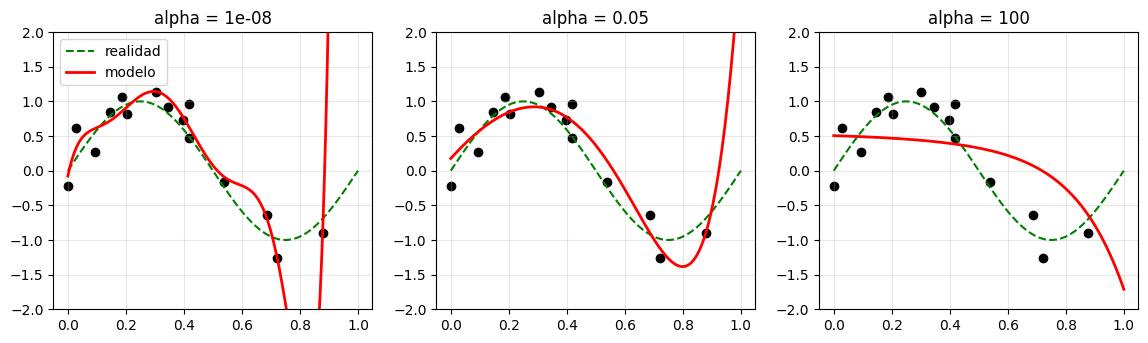

In [4]:
from sklearn.linear_model import Ridge

rng = np.random.RandomState(1)
x = np.sort(rng.uniform(0, 1, 15))
y = np.sin(2 * np.pi * x) + rng.normal(0, 0.25, 15)      # una onda con ruido
xs = np.linspace(0, 1, 200)

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, alpha in zip(ejes, [1e-8, 0.05, 100]):
    m = make_pipeline(PolynomialFeatures(9), StandardScaler(), Ridge(alpha=alpha))   # curva de grado 9 = muy flexible
    m.fit(x.reshape(-1, 1), y)
    ax.scatter(x, y, color="k")
    ax.plot(xs, np.sin(2 * np.pi * xs), "g--", label="realidad")
    ax.plot(xs, m.predict(xs.reshape(-1, 1)), "r", lw=2, label="modelo")
    ax.set_ylim(-2, 2)
    ax.set_title(f"alpha = {alpha}")
ejes[0].legend(); plt.show()

**Lectura:** a la izquierda el modelo hace "olas" absurdas para tocar cada punto (**overfitting**). Al centro la curva sigue la realidad (**punto justo**). A la derecha el freno es tan fuerte que la curva casi no se mueve (**underfitting**).

`Lasso` es igual a Ridge pero con otro tipo de freno: además de reducir coeficientes, **los puede dejar exactamente en 0**, o sea, *elimina variables inútiles*. `ElasticNet` mezcla ambos.

## 2. Regresión logística: cuando lo que predices es una categoría
Para "¿se va o se queda?" una recta no sirve porque la respuesta no es un número libre, es **0 o 1**. La **regresión logística** hace dos pasos:

1. Calcula un puntaje con una recta: `z = a + b₁·x₁ + b₂·x₂ ...` (puede ser cualquier número, positivo o negativo).
2. Pasa ese puntaje por la **curva sigmoide**, que lo convierte en una **probabilidad entre 0 y 1**.

Después aplicamos una regla: *si la probabilidad ≥ 0,5 (umbral), predecimos "se va"*. Ese umbral se puede mover (lo vimos en la presentación: bajarlo detecta más clientes que se van).

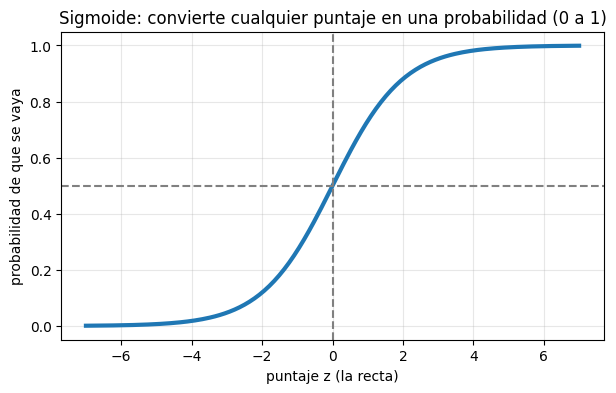

In [5]:
z = np.linspace(-7, 7, 200)
prob = 1 / (1 + np.exp(-z))
plt.plot(z, prob, lw=3)
plt.axhline(0.5, color="gray", ls="--"); plt.axvline(0, color="gray", ls="--")
plt.xlabel("puntaje z (la recta)"); plt.ylabel("probabilidad de que se vaya")
plt.title("Sigmoide: convierte cualquier puntaje en una probabilidad (0 a 1)")
plt.show()

### Ejemplo con números inventados
Supongamos que el modelo aprendió: `z = -3 + 0,9 × llamadas_a_soporte`. Mira cómo cambia la probabilidad:

In [6]:
soporte = np.arange(0, 8)
z = -3 + 0.9 * soporte
prob = 1 / (1 + np.exp(-z))
pd.DataFrame({"llamadas a soporte": soporte, "puntaje z": z.round(2), "probabilidad de irse": prob.round(2),
              "predicción (umbral 0.5)": np.where(prob >= .5, "SE VA", "se queda")})

,llamadas a soporte,puntaje z,probabilidad de irse,predicción (umbral 0.5)
0,0,-3.0,0.05,se queda
1,1,-2.1,0.11,se queda
2,2,-1.2,0.23,se queda
3,3,-0.3,0.43,se queda
4,4,0.6,0.65,SE VA
5,5,1.5,0.82,SE VA
6,6,2.4,0.92,SE VA
7,7,3.3,0.96,SE VA


Con 0 llamadas la probabilidad es ~5 %; con 4 llamadas, ~65 %; con 7, ~97 %. Cada llamada extra **empuja** la probabilidad hacia arriba. (Los coeficientes de este ejemplo son inventados para ilustrar; más abajo veremos los reales.)

## Preparar los datos reales (caso operadora móvil)
Usamos el mismo archivo de las semanas 3 y 4: `clientes_telecom.csv`. Queremos predecir `se_fue` (1 = el cliente se fue, 0 = se quedó).

Aquí solo hacemos lo indispensable: limpieza mínima, separar una parte para **validar** y convertir las columnas a números (rellenar vacíos, escalar y pasar categorías a 0/1). Si no entiendes esta celda, no importa: **ejecútala tal cual** y sigue.

In [7]:
# Cargamos el archivo desde el repositorio del curso.
# Si no hay internet, sube clientes_telecom.csv al panel de archivos de Colab y cambia URL por "clientes_telecom.csv".
URL = "https://raw.githubusercontent.com/jeanpier22/Diseno-de-Soluciones-de-Inteligencia-Artificial/main/Practica_Semana3y4/clientes_telecom.csv"
df = pd.read_csv(URL, encoding="utf-8-sig")

# Limpieza mínima (la misma de la Sesión 5)
df = df.drop_duplicates(subset="id_cliente").copy()
df.loc[(df["edad"] < 14) | (df["edad"] > 100), "edad"] = np.nan
df.loc[df["monto_factura"] < 0, "monto_factura"] = np.nan
df["tipo_plan"] = (df["tipo_plan"].str.lower().str.replace("-", "", regex=False)
                   .replace({"prepago": "Prepago", "postpago ilimitado": "Postpago Ilimitado", "postpago básico": "Postpago Básico"}))

num = ["edad", "consumo_datos_mb", "minutos_llamadas", "recargas_mes", "monto_factura",
       "velocidad_mbps", "caidas_red_mes", "llamadas_soporte", "satisfaccion"]
cat = ["tipo_plan", "metodo_pago", "departamento"]

train = df[df["particion"] == "train"]
X_train, y_train = train[num + cat], train["se_fue"]

# Del 'train' separamos una parte para VALIDAR (examen de práctica). El 'test' no se toca en este cuaderno.
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
], sparse_threshold=0)

Xp_tr = prep.fit_transform(X_tr)      # se 'aprende' solo con entrenamiento
Xp_val = prep.transform(X_val)
nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
print("Clientes para entrenar:", Xp_tr.shape[0], "| para validar:", Xp_val.shape[0], "| columnas:", Xp_tr.shape[1])
print("Proporción que se va:", round(y_tr.mean(), 3))

Clientes para entrenar: 900 | para validar: 300 | columnas: 31
Proporción que se va: 0.288


### Primer modelo logístico con parámetros por defecto
Entrenamos y miramos las métricas en validación. Recuerda: **exactitud** = % de aciertos; **precisión** = de los que dije "se va", cuántos de verdad se fueron; **recall** = de los que de verdad se fueron, cuántos detecté; **F1** = equilibrio entre precisión y recall; **AUC** = qué tan bien ordena a los que se van por encima de los que se quedan (1 = perfecto, 0,5 = azar).

In [8]:
from sklearn.linear_model import LogisticRegression

log = LogisticRegression(random_state=SEMILLA)
log.fit(Xp_tr, y_tr)
metricas(log, Xp_val, y_val)

exactitud    0.777
precisión    0.656
recall       0.465
F1           0.544
AUC          0.843
dtype: float64

## 3. Los parámetros de `LogisticRegression` (las "perillas")
| Parámetro | Qué hace en palabras simples | Por defecto | Qué pasa si lo cambias |
|---|---|---|---|
| **`C`** | **Fuerza de libertad del modelo** (inversa de la regularización). | `1.0` | `C` **chico** (0,01) → modelo con "freno": coeficientes pequeños, más simple (riesgo de underfitting). `C` **grande** (100) → sin freno: se ajusta mucho a los datos (riesgo de overfitting). |
| **`penalty`** | Tipo de freno: `"l2"` encoge coeficientes; `"l1"` los encoge y **deja algunos en 0** (elimina variables). | `"l2"` | `l1` sirve para *seleccionar variables*. Necesita `solver="liblinear"` o `"saga"`. |
| **`class_weight`** | Qué tan "caro" es equivocarse con cada clase. | `None` | `"balanced"` hace que fallar un cliente que se va pese más. **Sube el recall, baja la precisión.** |
| **`max_iter`** | Cuántos intentos máximos para encontrar los coeficientes. | `100` | Si ves el aviso *"ConvergenceWarning"*, súbelo (1000). No cambia el modelo, solo le da más tiempo. |
| **`solver`** | El "método de cálculo" interno. | `"lbfgs"` | Rara vez importa. `liblinear` para datos chicos y `l1`; `saga` para datos muy grandes. |
| **`fit_intercept`** | Si calcula el intercepto `a`. | `True` | Dejar en `True`. |
| **`random_state`** | Semilla para que el resultado sea repetible. | `None` | Fíjala (42) para obtener siempre lo mismo. |
| **`tol`** | Qué tan exacto debe ser el cálculo antes de parar. | `1e-4` | Casi nunca se toca. |

> **Regla práctica:** casi siempre basta con ajustar **`C`** y, si hay pocos clientes que se van, **`class_weight`**. Lo demás es secundario.

### Experimento A · `C`: el control de libertad
Probamos muchos valores de `C` y comparamos el desempeño con los datos de **entrenamiento** vs. **validación**. Si la nota de entrenamiento sube pero la de validación baja, hay overfitting.

,C,AUC entrenamiento,AUC validación,tamaño medio de los coeficientes
0,0.000,0.794,0.817,0.003
1,0.001,0.798,0.819,0.020
2,0.010,0.811,0.826,0.079
3,0.100,0.825,0.837,0.172
4,1.000,0.828,0.843,0.308
5,10.000,0.829,0.843,0.500
6,100.000,0.829,0.843,0.673
7,1000.000,0.829,0.843,0.812


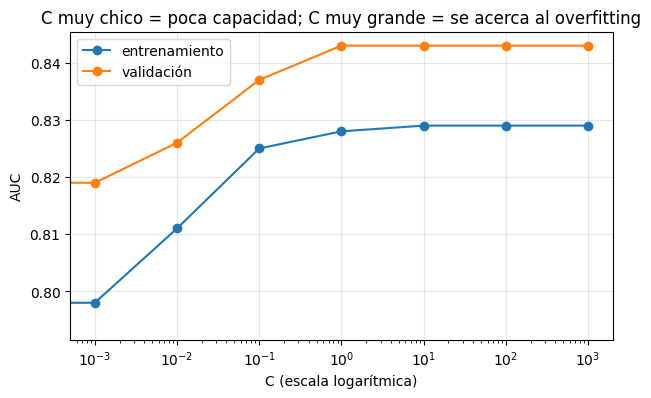

In [9]:
valores_C = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
filas = []
for C in valores_C:
    m = LogisticRegression(C=C, max_iter=2000, random_state=SEMILLA).fit(Xp_tr, y_tr)
    filas.append({"C": C,
                  "AUC entrenamiento": roc_auc_score(y_tr, m.predict_proba(Xp_tr)[:, 1]),
                  "AUC validación": roc_auc_score(y_val, m.predict_proba(Xp_val)[:, 1]),
                  "tamaño medio de los coeficientes": np.abs(m.coef_).mean()})
res_C = pd.DataFrame(filas).round(3)
display(res_C)

plt.semilogx(res_C["C"], res_C["AUC entrenamiento"], "o-", label="entrenamiento")
plt.semilogx(res_C["C"], res_C["AUC validación"], "o-", label="validación")
plt.xlabel("C (escala logarítmica)"); plt.ylabel("AUC"); plt.legend()
plt.title("C muy chico = poca capacidad; C muy grande = se acerca al overfitting")
plt.show()

**Cómo leerlo:**
* Con `C` muy pequeño (0,0001) los coeficientes son diminutos (mira la última columna: 0,003) y el modelo casi no aprende → **AUC más bajo** (~0,82 en validación): se queda corto (*underfitting* leve).
* Al subir `C` ambas notas mejoran y se **estabilizan** desde `C = 1` (~0,84 en validación). Los coeficientes siguen creciendo, pero el desempeño ya no cambia.
* **Observación honesta:** aquí el overfitting casi no aparece (la validación no cae). Con una recta y solo ~30 columnas, el modelo es tan simple que le cuesta memorizar. El overfitting fuerte lo verás en los **árboles, boosting y SVM**. Para modelos lineales, `C` pesa más cuando hay **muchísimas columnas** o muy pocos clientes.

En la Sesión 5 la validación cruzada (que es más confiable que una sola partición) eligió `C = 0,1`; la diferencia entre 0,1 y 1 es mínima.

### Experimento B · `penalty`: `l2` vs `l1` (eliminar variables)
Con `l1` algunos coeficientes se vuelven exactamente 0: el modelo decide que esas variables **no aportan**.

In [10]:
l2 = LogisticRegression(penalty="l2", C=0.1, max_iter=2000).fit(Xp_tr, y_tr)
l1 = LogisticRegression(penalty="l1", C=0.1, solver="liblinear").fit(Xp_tr, y_tr)

print("Coeficientes en 0 con l2:", int((l2.coef_ == 0).sum()), "de", l2.coef_.size)
print("Coeficientes en 0 con l1:", int((l1.coef_ == 0).sum()), "de", l1.coef_.size)
print()
sobreviven = pd.Series(l1.coef_[0], index=nombres)
print("Variables que l1 SÍ conserva (las importantes):")
print(sobreviven[sobreviven != 0].round(2).sort_values())
print()
print("AUC validación -> l2:", round(roc_auc_score(y_val, l2.predict_proba(Xp_val)[:, 1]), 3),
      "| l1:", round(roc_auc_score(y_val, l1.predict_proba(Xp_val)[:, 1]), 3))

Coeficientes en 0 con l2: 0 de 31
Coeficientes en 0 con l1: 20 de 31

Variables que l1 SÍ conserva (las importantes):
metodo_pago_Débito automático   -0.67
tipo_plan_Postpago Ilimitado    -0.39
satisfaccion                    -0.30
consumo_datos_mb                -0.20
minutos_llamadas                -0.19
tipo_plan_Postpago Básico       -0.11
velocidad_mbps                  -0.01
caidas_red_mes                   0.10
tipo_plan_Prepago                0.16
recargas_mes                     0.26
llamadas_soporte                 0.71
dtype: float64

AUC validación -> l2: 0.837 | l1: 0.83


Fíjate: `l1` logra casi la misma calidad usando **muchas menos variables**. Eso lo hace útil cuando tienes cientos de columnas y quieres saber cuáles importan.

### Experimento C · `class_weight`: darle más importancia a quienes se van
En este caso solo ~29 % de los clientes se va (clase minoritaria). Un modelo "normal" tiende a equivocarse más con esa clase. `class_weight="balanced"` le dice: *"fallar con alguien que se va cuenta más"*.

In [11]:
tabla = pd.DataFrame({
    "sin class_weight": metricas(LogisticRegression(C=0.1, max_iter=2000).fit(Xp_tr, y_tr), Xp_val, y_val),
    "balanced": metricas(LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000).fit(Xp_tr, y_tr), Xp_val, y_val),
    "peso 1 a 3": metricas(LogisticRegression(C=0.1, class_weight={0: 1, 1: 3}, max_iter=2000).fit(Xp_tr, y_tr), Xp_val, y_val),
})
tabla

,sin class_weight,balanced,peso 1 a 3
exactitud,0.790,0.760,0.743
precisión,0.709,0.559,0.534
recall,0.453,0.767,0.814
F1,0.553,0.647,0.645
AUC,0.837,0.835,0.836


**Lectura:** con `balanced` el **recall sube** (detectas a más clientes que se van) pero la **precisión baja** (más falsas alarmas). Es el mismo vaivén que vimos con el umbral. Se elige según el costo del negocio: ¿cuesta más una oferta innecesaria (S/ 20) o perder a un cliente (S/ 300)?

### Experimento D · ¿Por qué hay que escalar las variables?
Los modelos lineales comparan coeficientes. Si una variable está en miles (MB de datos) y otra en 1-5 (satisfacción), los coeficientes **no son comparables** y el cálculo se vuelve difícil. Por eso usamos `StandardScaler`. Mira la diferencia:

In [12]:
cols = ["consumo_datos_mb", "satisfaccion", "llamadas_soporte"]
Xn = X_tr[cols].fillna(X_tr[cols].median())

sin_escalar = LogisticRegression(max_iter=10000).fit(Xn, y_tr)
con_escalar = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000)).fit(Xn, y_tr)

pd.DataFrame({"coef. SIN escalar": sin_escalar.coef_[0],
              "coef. CON escalar": con_escalar[-1].coef_[0]}, index=cols).round(4)

,coef. SIN escalar,coef. CON escalar
consumo_datos_mb,-0.0001,-0.6135
satisfaccion,-0.3876,-0.3361
llamadas_soporte,0.5809,0.7685


**Lectura:** sin escalar, el coeficiente de `consumo_datos_mb` sale diminuto (0,0001) solo porque la variable tiene números enormes: parece "poco importante" cuando quizá no lo es. Escalada, todas están en la misma regla y se pueden comparar.

> **Moraleja:** en modelos lineales (y SVM) **siempre escala**. En árboles y boosting no hace falta.

## 4. Interpretar el modelo: la gran ventaja de los lineales
Cada coeficiente dice **hacia dónde empuja** esa variable:
* Coeficiente **positivo** → aumenta la probabilidad de que se vaya.
* Coeficiente **negativo** → la disminuye.
* Mientras más grande el valor absoluto (con variables escaladas), más influye.

Para decirlo en lenguaje de negocio se usa el **odds ratio** = `e^coeficiente`: "por cada aumento de una desviación estándar en la variable, las probabilidades de irse se **multiplican por** ese número".

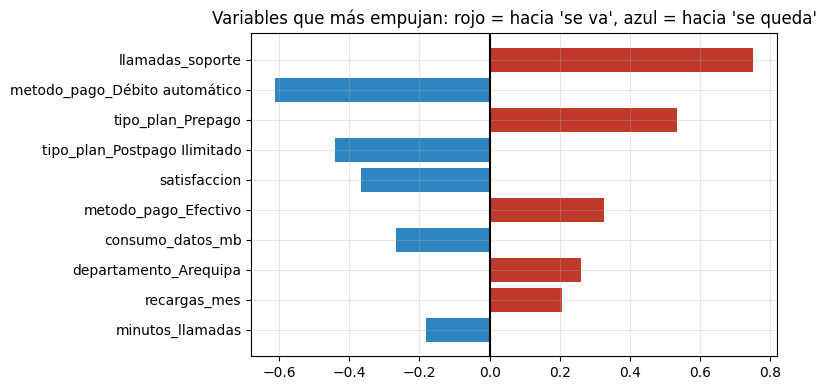

,coeficiente,odds ratio (e^coef)
llamadas_soporte,0.752,2.12
metodo_pago_Débito automático,-0.611,0.54
tipo_plan_Prepago,0.535,1.71
tipo_plan_Postpago Ilimitado,-0.441,0.64
satisfaccion,-0.366,0.69
metodo_pago_Efectivo,0.326,1.38
consumo_datos_mb,-0.267,0.77
departamento_Arequipa,0.260,1.30
recargas_mes,0.206,1.23
minutos_llamadas,-0.182,0.83


In [13]:
final = LogisticRegression(C=0.1, max_iter=2000, random_state=SEMILLA).fit(Xp_tr, y_tr)
coef = pd.Series(final.coef_[0], index=nombres)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index[::-1], top.values[::-1], color=["#c0392b" if v > 0 else "#2e86c1" for v in top.values[::-1]])
ax.axvline(0, color="k"); ax.set_title("Variables que más empujan: rojo = hacia 'se va', azul = hacia 'se queda'")
plt.tight_layout(); plt.show()

pd.DataFrame({"coeficiente": top.round(3), "odds ratio (e^coef)": np.exp(top).round(2)})

**Cómo explicarlo a un jefe (con los resultados de esta corrida):** *"cada llamada extra a soporte multiplica por ~2 las probabilidades de irse; los clientes de plan **Prepago** y los que pagan en **efectivo** tienen más riesgo; los que pagan con **débito automático**, tienen plan **Postpago Ilimitado** o están más **satisfechos** tienden a quedarse"*. (Si cambias la semilla o la partición, los valores exactos varían un poco.) Esto es oro para tomar decisiones: **un modelo lineal no solo predice, también explica**.

## 5. Cuando una recta no alcanza: datos no lineales
Una recta solo separa bien si los grupos se pueden dividir con una línea. Si un grupo rodea a otro (como un círculo), la recta fracasa. Solución sencilla: **crear nuevas variables** (por ejemplo, x², y², x·y) con `PolynomialFeatures`. El modelo sigue siendo lineal, pero ahora sobre variables más ricas.

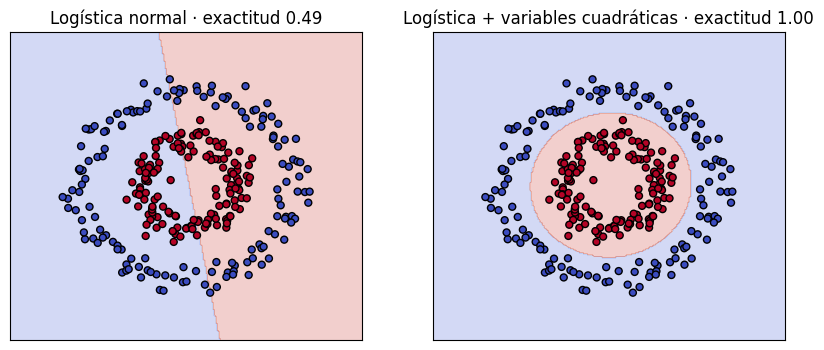

In [14]:
Xc, yc = make_circles(n_samples=300, noise=0.08, factor=0.45, random_state=1)

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
m1 = frontera(LogisticRegression(), Xc, yc, ejes[0])
ejes[0].set_title(f"Logística normal · exactitud {m1.score(Xc, yc):.2f}")
m2 = frontera(make_pipeline(PolynomialFeatures(2), LogisticRegression(C=10, max_iter=2000)), Xc, yc, ejes[1])
ejes[1].set_title(f"Logística + variables cuadráticas · exactitud {m2.score(Xc, yc):.2f}")
plt.show()

La primera acierta ~50 % (como lanzar una moneda); con variables cuadráticas llega a ~100 %. **Idea para el proyecto:** si tu modelo lineal se queda corto, no lo descartes sin antes probar crear variables nuevas; si aun así no alcanza, pasa a árboles, boosting o SVM con kernel (los otros cuadernos).

## 6. Resumen: ¿qué mover y cuándo?
| Síntoma que ves | Qué probar |
|---|---|
| Entrenamiento y validación **malas** (underfitting) | Subir `C`; agregar variables nuevas (`PolynomialFeatures`); usar un modelo más flexible. |
| Entrenamiento **muy buena**, validación **mala** (overfitting) | Bajar `C`; usar `penalty="l1"` para quitar variables; conseguir más datos. |
| Detecta pocos clientes que se van (recall bajo) | `class_weight="balanced"` o bajar el **umbral** de decisión. |
| Aviso `ConvergenceWarning` | Subir `max_iter` y/o escalar las variables. |
| Quieres explicar el modelo | Mirar `coef_` y odds ratios (¡ventaja de los lineales!). |

### Ventajas y límites
| ✅ Ventajas | ⚠️ Límites |
|---|---|
| Muy rápido, estable y fácil de explicar. | Solo capta relaciones "rectas" (sin ayuda de variables nuevas). |
| Sirve de **primer modelo de referencia** (baseline serio). | Sensible a variables con escalas muy distintas (hay que escalar). |
| Funciona bien con pocos datos. | Con muchas variables correlacionadas, los coeficientes pueden ser inestables (Ridge/Lasso ayudan). |

## 7. Ejercicios (para practicar)
1. Cambia `C` a `0.001` y a `100` en el "primer modelo logístico". ¿Qué pasa con el recall y la precisión?
2. Prueba `class_weight={0: 1, 1: 5}`. ¿Sube más el recall? ¿Cuánto baja la precisión?
3. En el Experimento B, prueba `C=0.01` con `l1`. ¿Cuántas variables sobreviven?
4. Cambia el umbral: calcula `prob = final.predict_proba(Xp_val)[:, 1]` y luego `pred = (prob >= 0.3)`. ¿Cómo cambian precisión y recall con `precision_score` y `recall_score`?
5. Para tu Evidencia 3: elige tu mejor `C` y redacta en 3 líneas **qué variables empujan hacia "se va"** usando el gráfico de la sección 4.